In [3]:
import pandas as pd
import numpy as np
import spacy
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.decomposition import TruncatedSVD, PCA
from sklearn.feature_selection import SelectKBest, chi2
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import MultinomialNB
from sklearn.model_selection import cross_val_predict, StratifiedKFold
from sklearn.metrics import precision_score, recall_score, f1_score, confusion_matrix
from sklearn.base import clone

nlp = spacy.load("en_core_web_sm")

def preprocess(text):
    doc = nlp(text.lower())
    tokens = [
        token.lemma_ for token in doc
        if not token.is_stop and not token.is_punct and len(token) > 2
    ]
    return " ".join(tokens)

train_df = pd.read_csv("DBLPTrainset.txt", sep="\t", header=None, names=["Label", "Title"])
test_df = pd.read_csv("DBLPTestset.txt", sep="\t", header=None, names=["Title"])
test_truth = pd.read_csv("DBLPTestGroundTruth.txt", sep="\t", header=None, names=["Label"])

train_df["Cleaned_Title"] = train_df["Title"].apply(preprocess)
test_df["Cleaned_Title"] = test_df["Title"].apply(preprocess)

y_train = train_df["Label"]
y_test = test_truth["Label"]

In [4]:
# ----------------------------
# Evaluation function with full cross-validation
# ----------------------------
def evaluate_model(X, y, name, model, k=5):
    cv = StratifiedKFold(n_splits=k, shuffle=True, random_state=42)
    precisions, recalls, f1s = [], [], []
    all_true, all_pred = [], []

    for train_idx, test_idx in cv.split(X, y):
        X_tr, X_val = X[train_idx], X[test_idx]
        y_tr, y_val = y.iloc[train_idx], y.iloc[test_idx]

        clf = clone(model)
        clf.fit(X_tr, y_tr)
        y_pred = clf.predict(X_val)

        all_true.extend(y_val)
        all_pred.extend(y_pred)

        precisions.append(precision_score(y_val, y_pred, average="micro", zero_division=0))
        recalls.append(recall_score(y_val, y_pred, average="micro", zero_division=0))
        f1s.append(f1_score(y_val, y_pred, average="micro", zero_division=0))

    print(f"\n=== {name} ===")
    print(f"Precision (micro): {np.mean(precisions):.4f}")
    print(f"Recall (micro):    {np.mean(recalls):.4f}")
    print(f"F1-score (micro):  {np.mean(f1s):.4f}")
    print("Confusion Matrix (aggregated):")
    print(confusion_matrix(all_true, all_pred))

    return {
        'Combination': name,
        'Precision': np.mean(precisions),
        'Recall': np.mean(recalls),
        'F1': np.mean(f1s)
    }

In [5]:
# ----------------------------
# Pipeline components
# ----------------------------
vectorizers = {
    "TF-IDF": TfidfVectorizer(
        max_features=5000, ngram_range=(1, 2), stop_words='english', min_df=3, max_df=0.85),
    "CountVectorizer": CountVectorizer(
        max_features=5000, ngram_range=(1, 2), stop_words='english', min_df=3, max_df=0.85)
}

reducers = {
    "None": None,
    "TruncatedSVD": TruncatedSVD(n_components=300, random_state=42),
    "PCA": "PCA",  # handled specially
    "Chi2": SelectKBest(chi2, k=300)
}

classifiers = {
    "LogisticRegression": LogisticRegression(max_iter=1000),
    "LinearSVM": LinearSVC(),
    "RandomForest": RandomForestClassifier(),
    "MultinomialNB": MultinomialNB()
}

In [6]:
# ----------------------------
# Run combinations
# ----------------------------
results = []

for vec_name, vectorizer in vectorizers.items():
    print(f"\n[Vectorizer] {vec_name}")
    X_vec = vectorizer.fit_transform(train_df["Cleaned_Title"])

    for red_name, reducer in reducers.items():
        print(f"  [Reducer] {red_name}")

        if red_name == "PCA":
            X_red = PCA(n_components=300, random_state=42).fit_transform(X_vec.toarray())
        elif reducer is None:
            X_red = X_vec
        else:
            X_red = reducer.fit_transform(X_vec, y_train)

        for clf_name, clf in classifiers.items():
            if clf_name == "MultinomialNB" and red_name != "None":
                continue  # Naive Bayes only works without reduction

            combo_name = f"{vec_name} + {red_name} + {clf_name}"
            print(f"    [Classifier] {clf_name} → Evaluating: {combo_name}")
            result = evaluate_model(X_red, y_train, combo_name, clf)
            results.append(result)

# ----------------------------
# Results summary
# ----------------------------
results_df = pd.DataFrame(results)
sorted_results = results_df.sort_values(by="F1", ascending=False)

print("\n=== All Combinations Sorted by F1 Score ===\n")
for _, row in sorted_results.iterrows():
    print(f"{row['Combination']}")
    print(f"  Precision: {row['Precision']:.4f}")
    print(f"  Recall:    {row['Recall']:.4f}")
    print(f"  F1 Score:  {row['F1']:.4f}")
    print("-" * 40)


[Vectorizer] TF-IDF
  [Reducer] None
    [Classifier] LogisticRegression → Evaluating: TF-IDF + None + LogisticRegression

=== TF-IDF + None + LogisticRegression ===
Precision (micro): 0.8610
Recall (micro):    0.8610
F1-score (micro):  0.8610
Confusion Matrix (aggregated):
[[3934  268   36  110  133]
 [ 218 7090  122   48   36]
 [  38  297 2194   65   84]
 [ 133  193   67 2912  373]
 [ 201  133  107  346 2505]]
    [Classifier] LinearSVM → Evaluating: TF-IDF + None + LinearSVM


C:\Users\Admin\anaconda3\Lib\site-packages\sklearn\svm\_classes.py:32: FutureWarning: The default value of `dual` will change from `True` to `'auto'` in 1.5. Set the value of `dual` explicitly to suppress the warning.
  warnings.warn(
C:\Users\Admin\anaconda3\Lib\site-packages\sklearn\svm\_classes.py:32: FutureWarning: The default value of `dual` will change from `True` to `'auto'` in 1.5. Set the value of `dual` explicitly to suppress the warning.
  warnings.warn(
C:\Users\Admin\anaconda3\Lib\site-packages\sklearn\svm\_classes.py:32: FutureWarning: The default value of `dual` will change from `True` to `'auto'` in 1.5. Set the value of `dual` explicitly to suppress the warning.
  warnings.warn(
C:\Users\Admin\anaconda3\Lib\site-packages\sklearn\svm\_classes.py:32: FutureWarning: The default value of `dual` will change from `True` to `'auto'` in 1.5. Set the value of `dual` explicitly to suppress the warning.
  warnings.warn(
C:\Users\Admin\anaconda3\Lib\site-packages\sklearn\svm\_clas


=== TF-IDF + None + LinearSVM ===
Precision (micro): 0.8631
Recall (micro):    0.8631
F1-score (micro):  0.8631
Confusion Matrix (aggregated):
[[3953  195   48  127  158]
 [ 250 6984  158   67   55]
 [  46  198 2260   78   96]
 [ 142  118   91 2948  379]
 [ 210   80  122  346 2534]]
    [Classifier] RandomForest → Evaluating: TF-IDF + None + RandomForest


KeyboardInterrupt: 

In [12]:
import pandas as pd
import spacy
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# ----------------------------
# Load spaCy and define preprocessing
# ----------------------------
nlp = spacy.load("en_core_web_sm")

def preprocess(text):
    doc = nlp(text.lower())
    tokens = [
        token.lemma_ for token in doc
        if not token.is_stop and not token.is_punct and len(token) > 2
    ]
    return " ".join(tokens)

# ----------------------------
# Load data
# ----------------------------
train_df = pd.read_csv("DBLPTrainset.txt", sep="\t", header=None, names=["Label", "Title"])
test_df = pd.read_csv("DBLPTestset.txt", sep="\t", header=None, names=["Title"])
test_truth = pd.read_csv("DBLPTestGroundTruth.txt", sep="\t", header=None, names=["Label"])
y_test = test_truth["Label"]

# ----------------------------
# Preprocess titles
# ----------------------------
train_df["Cleaned_Title"] = train_df["Title"].apply(preprocess)
test_df["Cleaned_Title"] = test_df["Title"].apply(preprocess)

# ----------------------------
# TF-IDF vectorization
# ----------------------------
vectorizer = TfidfVectorizer(
    max_features=5000,
    ngram_range=(1, 2),
    stop_words='english',
    min_df=3,
    max_df=0.85
)

X_train = vectorizer.fit_transform(train_df["Cleaned_Title"])
X_test = vectorizer.transform(test_df["Cleaned_Title"])
y_train = train_df["Label"]

# Train final model
model = LinearSVC()
model.fit(X_train, y_train)

# Predict on test set
y_pred = model.predict(X_test)


# Evaluation
print("=== FINAL TEST SET EVALUATION ===\n")
print("Classification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

print("Confusion Matrix:")
cm = confusion_matrix(y_test, y_pred)
print(cm)

C:\Users\Admin\anaconda3\Lib\site-packages\sklearn\svm\_classes.py:32: FutureWarning: The default value of `dual` will change from `True` to `'auto'` in 1.5. Set the value of `dual` explicitly to suppress the warning.
  warnings.warn(


=== FINAL TEST SET EVALUATION ===

Classification Report:
              precision    recall  f1-score   support

     INFOCOM       0.77      0.76      0.77       502
       ISCAS       0.96      0.92      0.94      2043
    SIGGRAPH       0.69      0.82      0.75       186
        VLDB       0.56      0.77      0.65       219
         WWW       0.79      0.74      0.77       423

    accuracy                           0.86      3373
   macro avg       0.75      0.80      0.77      3373
weighted avg       0.87      0.86      0.86      3373

Confusion Matrix:
[[ 384   34   14   29   41]
 [  76 1879   34   46    8]
 [   2   17  153    9    5]
 [  10    6    6  169   28]
 [  29   17   14   49  314]]


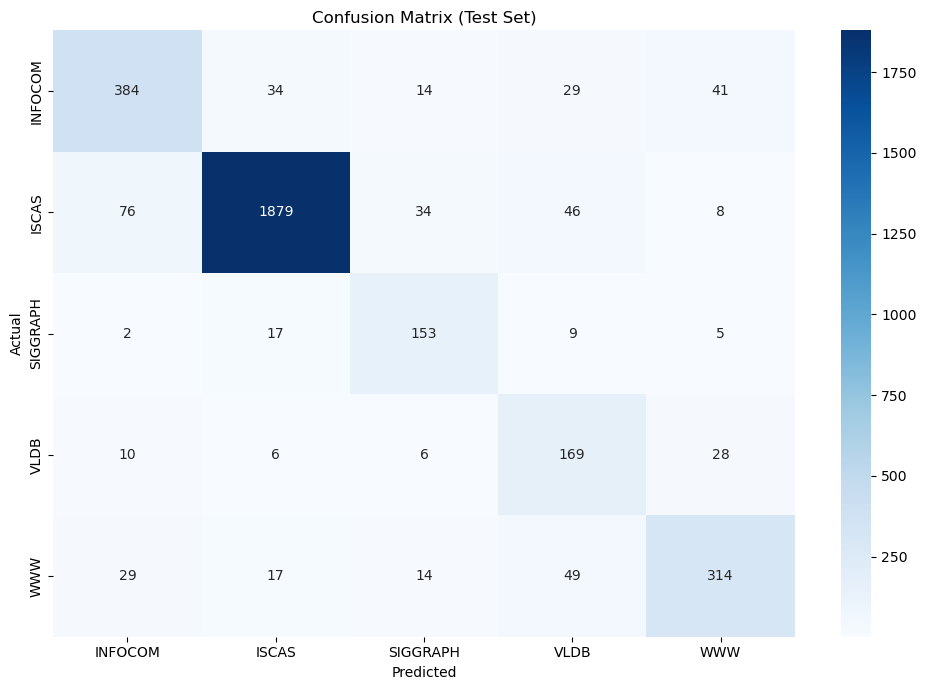

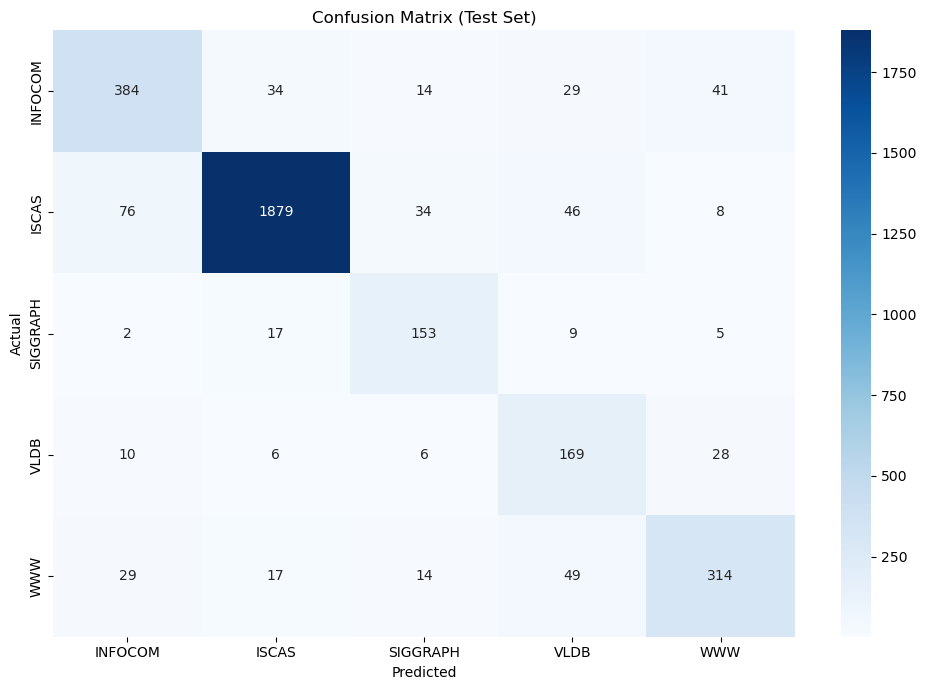

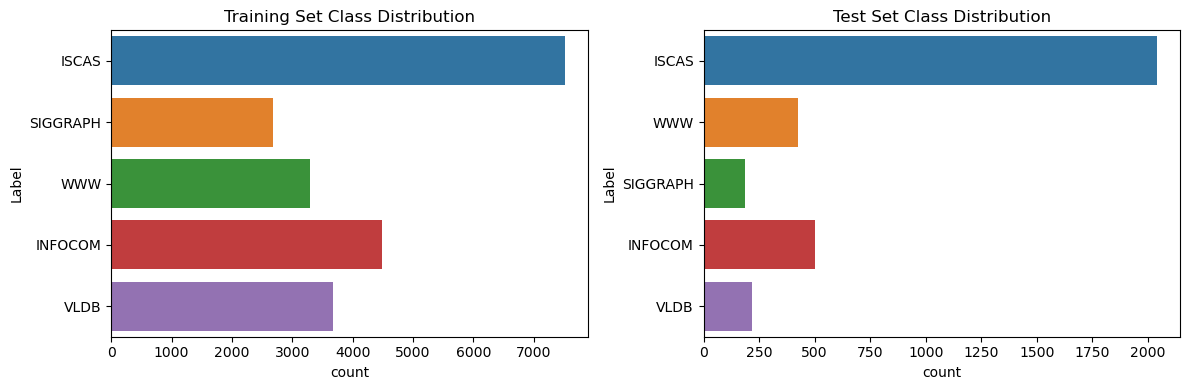


Top features for class 'INFOCOM':
  network
  packet
  multicast
  bgp
  tcp
  routing
  queue
  forwarding
  manet
  vehicular

Top features for class 'ISCAS':
  circuit
  cmos
  noc
  amplifier
  fpga
  chip
  converter
  264
  voltage
  decoder

Top features for class 'SIGGRAPH':
  animation
  rendering
  radiosity
  display
  art
  surface
  panel session
  haptic
  ray
  graphic

Top features for class 'VLDB':
  database
  dbms
  datum base
  datum
  sql
  internet scale
  join
  road network
  transaction
  oracle

Top features for class 'WWW':
  web
  advertising
  ontology
  rdf
  xslt
  review
  browser
  www
  topic
  owl


In [14]:
# ----------------------------
# Confusion Matrix Heatmap
# ----------------------------
def plot_conf_matrix(cm, labels):
    plt.figure(figsize=(10, 7))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=labels, yticklabels=labels)
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.title("Confusion Matrix (Test Set)")
    plt.tight_layout()
    plt.show()

plot_conf_matrix(cm, sorted(y_test.unique()))

# ----------------------------
# Class Distribution Plot
# ----------------------------
def plot_class_distribution(y_train, y_test):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    sns.countplot(y=y_train, ax=axes[0])
    axes[0].set_title("Training Set Class Distribution")
    sns.countplot(y=y_test, ax=axes[1])
    axes[1].set_title("Test Set Class Distribution")
    plt.tight_layout()
    plt.show()

# ----------------------------
# Top TF-IDF Features Per Class
# ----------------------------
def show_top_tfidf_features(vectorizer, model, class_labels, top_n=10):
    feature_names = np.array(vectorizer.get_feature_names_out())
    for i, class_label in enumerate(class_labels):
        top_indices = np.argsort(model.coef_[i])[-top_n:]
        print(f"\nTop features for class '{class_label}':")
        for feat in feature_names[top_indices][::-1]:
            print(f"  {feat}")

# ----------------------------
# Call All Visualizations
# ----------------------------
labels = sorted(y_test.unique())
plot_conf_matrix(cm, labels)
plot_class_distribution(y_train, y_test)
show_top_tfidf_features(vectorizer, model, model.classes_, top_n=10)
